# PV displacement strength: how does the catalogue signal depend on A?

**25 independent Gaussian ICs**, matched across $A=0, 0.25, 0.5, 1, 2, 4, 8, 16, 24, 32, 48, 64, 96, 128, 256\ h^{-1}\mathrm{Mpc}$ and helicities $\epsilon=-1,0,+1$. The box is $1000\ h^{-1}\mathrm{Mpc}$, the field mesh is $256^3$, and the particle lattice is $32^3$. Lengths are interpreted as **comoving**.

Only $A$ changes. The density field, unit helical fields, spectrum, lattice, and shape-selection bounds are shared across amplitudes within each IC. All earlier fields and catalogues are reused; only newly added amplitudes require triangulation.

In [1]:
from pathlib import Path
import html,json,sys
import numpy as np
from IPython.display import display,Markdown,HTML
PROJECT=Path('/home/users/h/hes/projects/2026_DT_Parity')
RUN=Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261121_mesh_ic_L1000_N256_A_extended')
# Use the analysis implementation frozen with this experiment.
sys.path.insert(0,str(RUN/"code/src"))
from parity_study.storage import digest
from parity_study.amplitude_scan import response_figure,helicity_figure,ranking_figure
OUT=Path('/home/users/h/hes/scratch/projects/cosmicPV/field_PVdisp_A/extended')
protocol=json.loads((OUT/"protocol.json").read_text())
report=json.loads((OUT/"analysis.json").read_text())
assert report["complete"] and digest(OUT/"protocol.json")==report["protocol_sha256"]
audit=report["independent_ic_audit"]
assert audit["passed"]
display(Markdown(f"**Complete:** {audit['checked_catalogues']} catalogues across {len(report['seeds'])} independent ICs. "
                 "Matched particle maps and distinct density/ZA/helical fields verified."))
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":110,"font.size":11,"axes.grid":True,"grid.alpha":.2})
(OUT/"figures").mkdir(parents=True,exist_ok=True)
def save_figure(fig,name):
    for ax in fig.axes:
        if ax.get_xscale()=="symlog":
            ax.set_xlim(0,max(report["amplitudes"])*1.15)
    for ext in ("png","pdf"):
        fig.savefig(OUT/"figures"/f"{name}.{ext}",dpi=170,bbox_inches="tight")
    plt.show()
    plt.close(fig)

def show_table(rows, columns):
    """Display a compact table; columns are (dictionary key, displayed heading)."""
    if not rows:
        display(Markdown("No measurements available for this section."))
        return
    def fmt(value):
        if value is None:
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.5g}"
        return str(value)
    heading = "".join(f"<th>{html.escape(title)}</th>" for _, title in columns)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(fmt(row.get(key)))}</td>" for key, _ in columns) + "</tr>"
        for row in rows)
    display(HTML("<div style='overflow-x:auto'><table><thead><tr>" + heading +
                 "</tr></thead><tbody>" + body + "</tbody></table></div>"))

**Complete:** 1075 catalogues across 25 independent ICs. Matched particle maps and distinct density/ZA/helical fields verified.

## 1. What is a physically meaningful A?

The **displacement strength** $A$ is an ensemble RMS length:
$$
P_{{\rm hel},\mathbf k}=A^2W_{\mathbf k},\qquad \sum_{\mathbf k}W_{\mathbf k}=1,
\qquad A^2=\mathbb E\langle|\boldsymbol\Psi_{\rm hel}|^2\rangle.
$$
Thus $A=2$ means an RMS helical displacement of $2\ h^{-1}\mathrm{Mpc}$; individual realizations fluctuate. Mesh spacing is a resolution scale. A physical choice of $A$ requires a displacement spectrum and its normalization at the epoch of interest. Our spectrum is still a **controlled toy model**, so this scan tests sensitivity without assigning a cosmological preferred A.

Useful comparisons are $A/\Delta x$ (mesh spacing), $A/\ell_p$ (particle spacing), and $A/\sigma_{\rm ZA}$ (ensemble RMS ZA displacement). A coherent displacement can exceed a mesh cell; deformation also depends on spatial gradients. Define $k_{\rm rms}=\sqrt{\sum_{\mathbf k}k^2W_{\mathbf k}}$: $A k_{\rm rms}$ is the ensemble RMS norm of the helical displacement gradient. Small values describe weak helical deformation; this is a diagnostic, not a convergence test.

[Shim et al., Eqs. 6–8](https://arxiv.org/html/2406.06080v2) tie the smoothing length to a physical protohalo scale and choose a spectrum normalization. Their $\sigma_{\mathcal R}$ is not our RMS-length $A$. A resolution study should hold A and the physical spectrum/band fixed while changing mesh or particle resolution.

In [2]:
sc=report["physical_scales"]
show_table([
    dict(scale="Mesh spacing Δx = L/Nmesh",value=sc["mesh_spacing"]),
    dict(scale="Particle spacing ℓp = L/Nparticle",value=sc["particle_spacing"]),
    dict(scale="Helical smoothing Rh",value=sc["smoothing"]),
    dict(scale="Ensemble RMS ZA displacement σZA",value=sc["expected_za_rms"]),
    dict(scale="Inverse RMS helical wavenumber 1/krms",value=sc["inverse_k_rms_length"])
],[("scale","Length scale"),("value","h⁻¹ Mpc")])
show_table(report["scales"],[("A","A [h⁻¹ Mpc]"),("A_over_mesh","A/Δx"),
    ("A_over_particle","A/ℓp"),("A_over_ZA","A/σZA"),("rms_helical_gradient","A krms")])
display(Markdown(f"Active modes reach **kmax = {sc['kmax']:.5f} h Mpc⁻¹**, limited by the 32³ particle lattice. "
                 "The 256³ mesh alone does not set the resolved physical band."))

Length scale,h⁻¹ Mpc
Mesh spacing Δx = L/Nmesh,3.9062
Particle spacing ℓp = L/Nparticle,31.25
Helical smoothing Rh,6.25
Ensemble RMS ZA displacement σZA,3.547
Inverse RMS helical wavenumber 1/krms,50.773


A [h⁻¹ Mpc],A/Δx,A/ℓp,A/σZA,A krms
0,0,0,0,0
0.25,0.064,0.008,0.070482,0.0049239
0.5,0.128,0.016,0.14096,0.0098478
1,0.256,0.032,0.28193,0.019696
2,0.512,0.064,0.56385,0.039391
4,1.024,0.128,1.1277,0.078782
8,2.048,0.256,2.2554,0.15756
16,4.096,0.512,4.5108,0.31513
24,6.144,0.768,6.7662,0.47269
32,8.192,1.024,9.0217,0.63026


Active modes reach **kmax = 0.10053 h Mpc⁻¹**, limited by the 32³ particle lattice. The 256³ mesh alone does not set the resolved physical band.

## 2. Which tetrahedra and which signal?

Choose the reference vertex by the smallest sum of squared distances to the other three vertices. For its three edge vectors $\mathbf v_a$, define
$$
\widehat\chi=\frac{\mathbf v_1\cdot(\mathbf v_2\times\mathbf v_3)}{|\mathbf v_1||\mathbf v_2||\mathbf v_3|},\qquad
B:\quad 0.6905111410000623\leq r=\ell_{\min}/\ell_{\max}<0.7567675934849439.
$$
The edge vectors follow the distance-based vertex ordering defined in [the fiducial notebook](field_PVdisp.ipynb); $\ell_{\min}$ and $\ell_{\max}$ refer to those **three reference-vertex edges**. Keep both chirality signs, using these unchanged shape bounds at every A. The comparison also includes all tetrahedra.

For IC $s$, let $S_{s,B}(\epsilon;A)$ be the mean $\widehat\chi$ of its selected tetrahedra and
$$D_{s,B}(A)=S_{s,B}(+1;A)-S_{s,B}(-1;A).$$
At $A=0$ all helicities share the same ZA-only catalogue: $D=0$ exactly, by construction.

## 3. Catalogue signal versus displacement strength

Each point is the mean catalogue signal over 25 ICs. Bars show one **standard error of the mean (SEM)**: the sample standard deviation across ICs divided by $\sqrt{25}$. The ε=0 catalogue has equal expected power in the two helical components at the same A.

The horizontal axis is logarithmic above A=1 and linear near A=0.

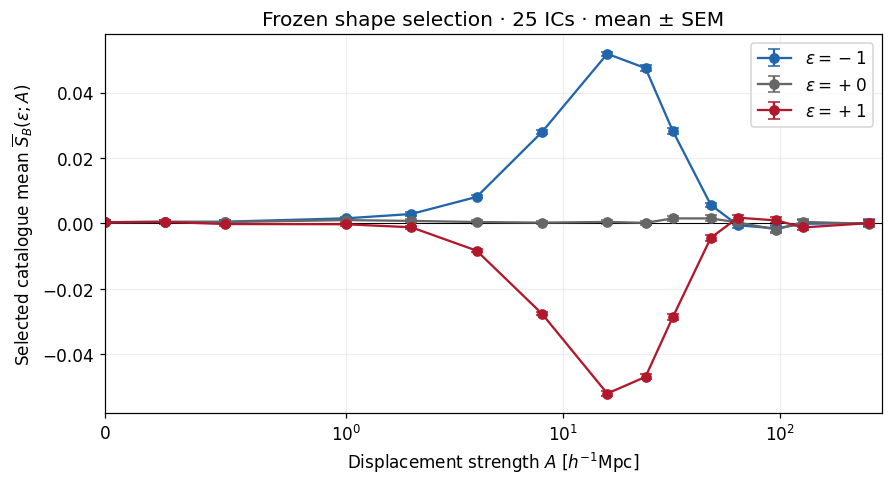

In [3]:
save_figure(helicity_figure(report),"catalogue_signal_vs_A")

## 4. Does the helicity difference increase with A?

Compute the +1 minus −1 difference within each matched IC, then average. The plot shows $\overline D_B(A)\pm1\,\mathrm{SEM}$. Negative values mean the positive-helicity catalogue has the lower chirality signal. Amplitudes are correlated because they share ICs; the full covariance and paired contrasts against A=2 are saved.

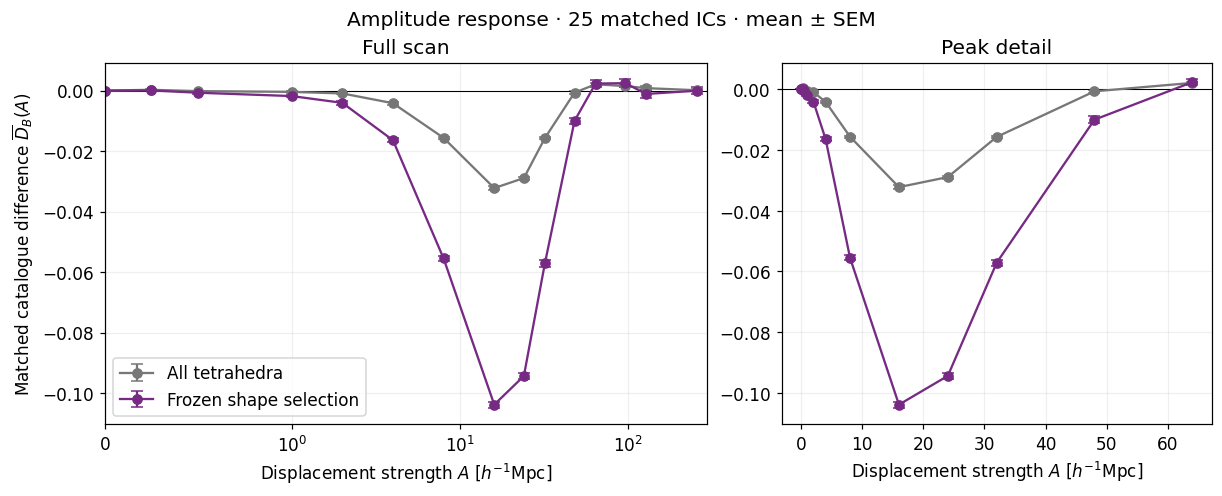

A [h⁻¹ Mpc],Mean D̄B,SEM,Fraction retained,p (14-A correction)
0,0,0,0.3343,—
0.25,4.3735e-05,0.00028213,0.33423,1
0.5,-0.0007146,0.00034517,0.33419,0.69091
1,-0.0018126,0.0003665,0.33392,0.00066775
2,-0.004055,0.00056375,0.33257,2.7517e-06
4,-0.016415,0.00058837,0.32665,1.1746e-18
8,-0.055509,0.00083496,0.30323,1.3934e-27
16,-0.10384,0.00096311,0.24944,1.3227e-32
24,-0.094364,0.0010675,0.21754,1.5342e-30
32,-0.057119,0.0010444,0.19489,1.4648e-25


**Smallest tested A with a same-sign selected response and corrected p < 0.05:** **1 h⁻¹ Mpc**.

In [4]:
save_figure(response_figure(report),"helicity_difference_vs_A")
selected=[r for r in report["summaries"] if r["selection"]==report["primary_selection"]]
show_table(selected,[("A","A [h⁻¹ Mpc]"),("mean","Mean D̄B"),("sem","SEM"),
    ("retained_fraction","Fraction retained"),("p_amplitude_bonferroni","p (14-A correction)")])
first=report["first_detected_A"]
display(Markdown(f"**Smallest tested A with a same-sign selected response and corrected p < 0.05:** "
                 f"**{first:g} h⁻¹ Mpc**." if first is not None else
                 "**No tested A gives a same-sign selected response after the 14-A correction.**"))

## 5. Which tested A works best?

Compare **signal magnitude** $|\overline D_B|$ with the **detection score** $|\overline D_B|/\mathrm{SEM}$ (the absolute paired t statistic). The latter describes this 25-IC experiment, not a Gaussian-sigma calibration. Their maxima can differ.

Resample the 25 ICs jointly across A, 10,000 times. The fraction of resamples choosing each A describes ranking stability. These are exploratory comparisons on reused ICs; a preferred A needs fresh confirmation. The fixed shape cut was chosen at A=2 and is not reoptimized here.

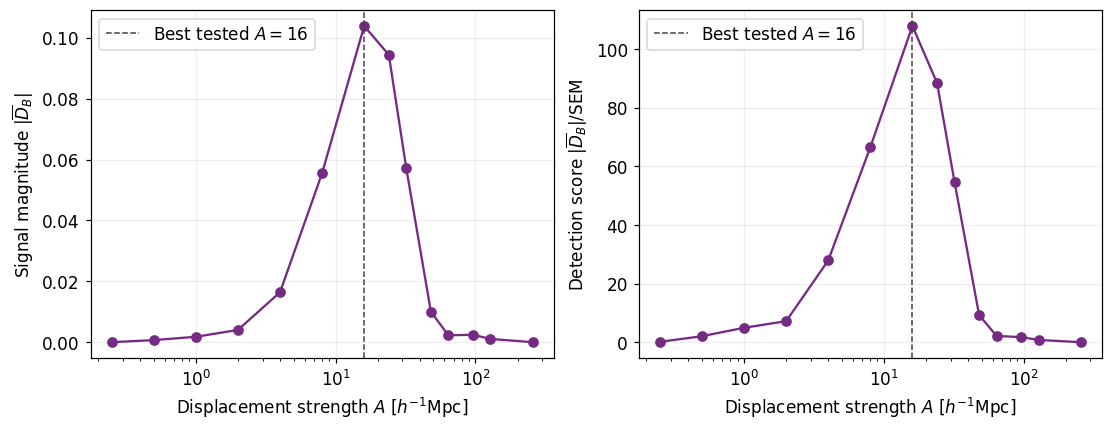

A [h⁻¹ Mpc],|D̄B|,|D̄B| / SEM,Fraction best |D̄B|,Fraction best score
0.25,4.3735e-05,0.15502,0,0
0.5,0.0007146,2.0703,0,0
1,0.0018126,4.9458,0,0
2,0.004055,7.1928,0,0
4,0.016415,27.898,0,0
8,0.055509,66.481,0,0.0054
16,0.10384,107.81,1,0.8998
24,0.094364,88.399,0,0.0946
32,0.057119,54.692,0,0.0002
48,0.010022,9.2468,0,0


**Largest measured signal:** A=16; **largest detection score:** A=16 h⁻¹ Mpc. Amplitudes not distinguished from the signal maximum by the corrected paired comparisons: 16.

**Both measured maxima lie inside the tested range.** This identifies candidates on this grid, not an exact continuous optimum.

At the signal maximum: A/σZA=4.51, A/ℓp=0.51, and A·krms=0.32. Strong helical deformation can occur when A·krms approaches or exceeds one; this toy IC response does not establish a cosmologically realistic amplitude.

In [5]:
opt=report["optimization"]
save_figure(ranking_figure(report),"amplitude_ranking")
show_table(opt["scores"],[("A","A [h⁻¹ Mpc]"),("absolute_mean","|D̄B|"),("snr","|D̄B| / SEM"),
    ("bootstrap_best_magnitude","Fraction best |D̄B|"),("bootstrap_best_snr","Fraction best score")])
display(Markdown(f"**Largest measured signal:** A={opt['best_magnitude_A']:g}; "
    f"**largest detection score:** A={opt['best_snr_A']:g} h⁻¹ Mpc. "
    f"Amplitudes not distinguished from the signal maximum by the corrected paired comparisons: "
    + ", ".join(f"{a:g}" for a in opt["not_distinguished_from_magnitude_peak"])+"."))
if opt["magnitude_peak_at_upper_boundary"] or opt["snr_peak_at_upper_boundary"]:
    display(Markdown("**At least one maximum is still at the upper boundary; its turnover is not bracketed.**"))
else:
    display(Markdown("**Both measured maxima lie inside the tested range.** This identifies candidates on this grid, not an exact continuous optimum."))
best=next(r for r in report["scales"] if r["A"]==opt["best_magnitude_A"])
display(Markdown(f"At the signal maximum: A/σZA={best['A_over_ZA']:.2f}, A/ℓp={best['A_over_particle']:.2f}, "
    f"and A·krms={best['rms_helical_gradient']:.2f}. Strong helical deformation can occur when A·krms approaches or exceeds one; "
    "this toy IC response does not establish a cosmologically realistic amplitude."))

The signed-response comparisons use all 91 pairs of nonzero amplitudes with a Bonferroni correction, allowing comparisons to the data-selected maximum. The grid was extended after seeing the first scan, so this remains exploratory. Numerical convergence needs a separate resolution test.

[Frozen protocol](saved/field_PVdisp_A/extended/protocol.json) · [Catalogue measurements](saved/field_PVdisp_A/extended/catalogues.csv) · [All paired contrasts](saved/field_PVdisp_A/extended/all_pair_contrasts.csv) · [Arrays and covariance](saved/field_PVdisp_A/extended/amplitude_scan.npz) · [Figures](saved/field_PVdisp_A/extended/figures/)